# Google Quick, Draw! - Feature Subsets, PCA and Clustering

**Rules followed.** Everything is learned on the 19,200 training images. Classifiers are scored on the 2,400 validation images. The test set is not loaded. Seed 42 everywhere. Classifier settings are the validated ones from the classical models notebook (k-NN k=5, Logistic Regression C=0.1).

## 1. Setup

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_score, completeness_score,
                             silhouette_score)

SEED = 42
np.random.seed(SEED)

root = Path("..")                                   # this notebook lives in notebooks/
data_path   = root / "data" / "quickdraw" / "quickdraw_8class_processed.npz"
results_dir = root / "results"
figures_dir = root / "figures"
results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)

## 2. Load training and validation data (flattened to 784 pixels)

In [2]:
data = np.load(data_path, allow_pickle=True)
# only train and validation are loaded: the test set stays sealed
X_tr = data["X_train"].reshape(len(data["X_train"]), -1)     # (19200, 784), values already in 0-1
y_tr = data["y_train"]
X_va = data["X_val"].reshape(len(data["X_val"]), -1)         # (2400, 784)
y_va = data["y_val"]
categories = [str(c) for c in data["categories"]]
n_classes, n_pixels = len(categories), X_tr.shape[1]
print("train", X_tr.shape, "val", X_va.shape, "| classes:", categories)
assert X_tr.shape == (19200, 784) and X_va.shape == (2400, 784)

train (19200, 784) val (2400, 784) | classes: ['airplane', 'apple', 'bicycle', 'cat', 'fish', 'guitar', 'house', 'tree']


## 3. Per-class correlation 

For each class, the labels are turned into 1 (this class) and 0 (all other classes). Then every pixel is correlated with that 0/1 column. The **size** of the correlation matters, not its sign, so absolute values are used. Correlations are computed on the training set only.

We have labels from 0 to 7, but those are just names for the classes (airplane = 0, apple = 1,... tree = 7). Tree is not 'bigger' than airplane and if we had listed the classes in a different order all the numbers would change. The Pearson correlation calculates as if the label was a real number, so if we correlate each pixel directly with the 0-7 label, the outcome would depend on whatever order we happened to put the classes in, which doesn’t mean anything. To fix this we make a one vs rest label for each class: 1 if the drawing is that class and 0 if it is any of the other 7 (e.g. “cat or not cat”). Matching each pixel to that 0/1 column tells us something concrete: how much that pixel helps distinguish one class from all the others. We also have a separate map for each class, so we can see which parts of the image are important for each.

We take the absolute value because a pixel can be useful in two different ways. A positive correlation means that the pixel is usually drawn in for that class . For example, in the middle of the apple map, there is a bright spot where the round body of the apple is usually found. A negative correlation means that the pixel is mostly empty for that class compared to the others. Both of these are helpful to separate the class from the others, so a strong negative correlation is as useful as a strong positive one. What matters is not the direction of the relationship but its strength. The absolute value also matters for the “general” map, which averages the correlations over all 8 classes. Without it, a pixel that is very positive for one class and very negative for another could average out to about zero and look useless, yet it’s actually really informative.

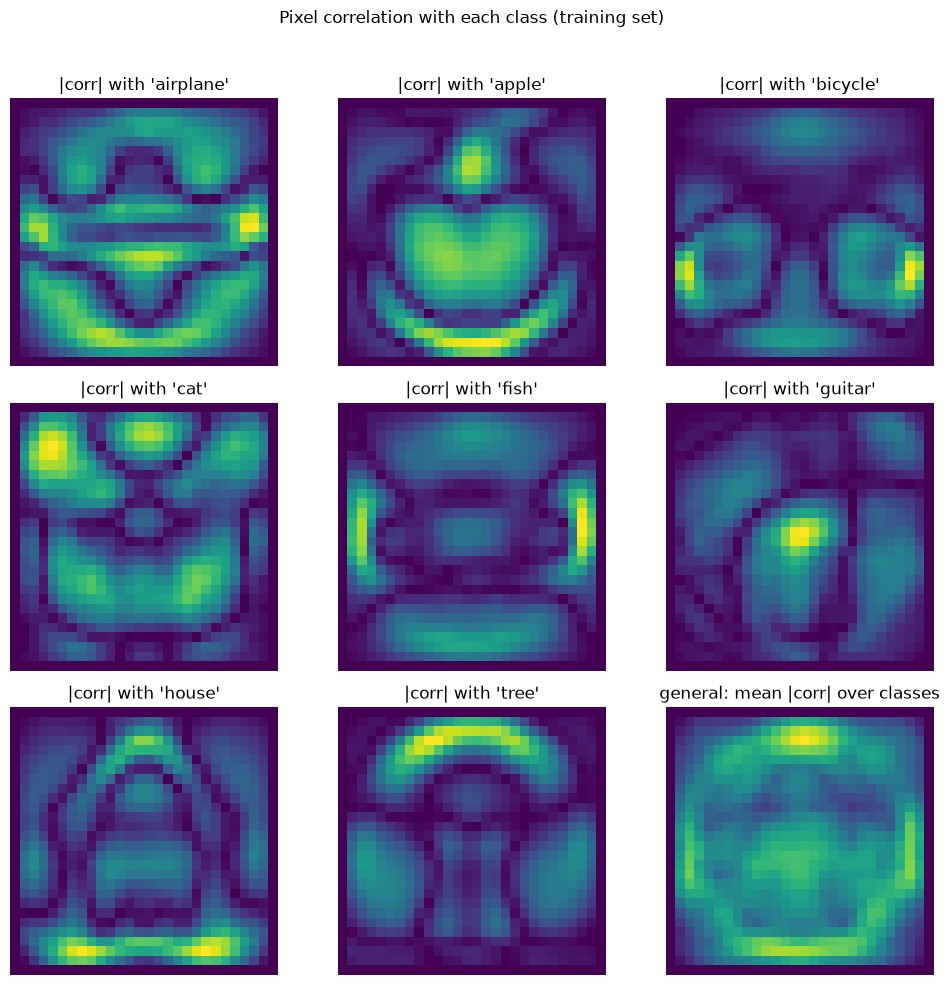

strongest single pixel per class:
  airplane  pixel 389 (row 13, col 25)  corr +0.230
  apple     pixel 715 (row 25, col 15)  corr +0.375
  bicycle   pixel 529 (row 18, col 25)  corr +0.420
  cat       pixel 116 (row  4, col  4)  corr +0.224
  fish      pixel 361 (row 12, col 25)  corr +0.398
  guitar    pixel 378 (row 13, col 14)  corr +0.398
  house     pixel 720 (row 25, col 20)  corr +0.384
  tree      pixel  93 (row  3, col  9)  corr +0.503


In [3]:
def class_correlations(X, y, n_classes):
    """Pearson correlation of every pixel with the one-vs-rest 0/1 label of every class. Returns (n_classes, n_pixels)."""
    Xc = X - X.mean(axis=0)
    sx = np.sqrt((Xc ** 2).sum(axis=0))
    out = np.zeros((n_classes, X.shape[1]))
    for c in range(n_classes):
        yc = (y == c).astype(float)
        yc -= yc.mean()
        denom = sx * np.sqrt((yc ** 2).sum())
        # pixels that are always 0 (image border) have zero variance: give them correlation 0, not NaN
        out[c] = np.divide(Xc.T @ yc, denom, out=np.zeros(X.shape[1]), where=denom > 0)
    return out

corr = class_correlations(X_tr, y_tr, n_classes)            # signed
abs_corr = np.abs(corr)
general = abs_corr.mean(axis=0)                             # "general" importance: mean |corr| over the 8 classes

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for c, ax in enumerate(axes.ravel()[:n_classes]):
    im = ax.imshow(abs_corr[c].reshape(28, 28), cmap="viridis")
    ax.set_title(f"|corr| with '{categories[c]}'")
    ax.axis("off")
ax = axes.ravel()[-1]
ax.imshow(general.reshape(28, 28), cmap="viridis")
ax.set_title("general: mean |corr| over classes")
ax.axis("off")
fig.suptitle("Pixel correlation with each class (training set)")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(figures_dir / "quickdraw_pixel_correlation_maps.png", dpi=150)
plt.show()

print("strongest single pixel per class:")
for c in range(n_classes):
    j = int(abs_corr[c].argmax())
    print(f"  {categories[c]:9s} pixel {j:3d} (row {j//28:2d}, col {j%28:2d})  corr {corr[c, j]:+.3f}")

## 4. Three feature subsets (top 2, 5 and 10 pixels per class) plus a random control

All 784 pixels                           -> 784 features
Top 2 per class                          ->  15 features
Top 5 per class                          ->  38 features
Top 10 per class                         ->  77 features
Random 15 pixels (control for top 2)     ->  15 features
Random 38 pixels (control for top 5)     ->  38 features
Random 77 pixels (control for top 10)    ->  77 features


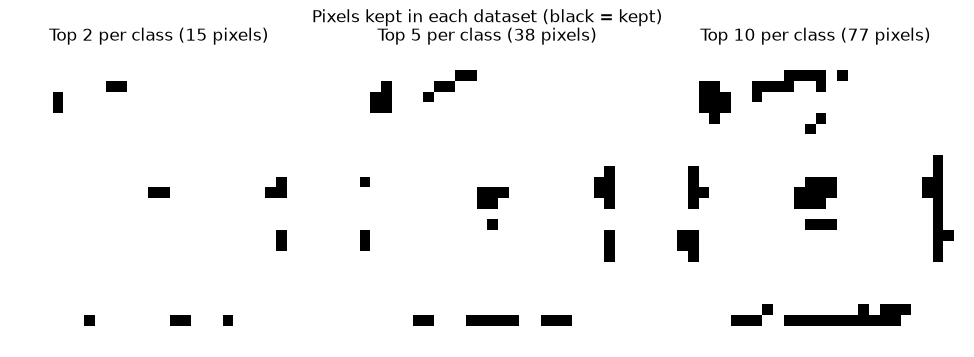

In [4]:
def top_k_pixels(abs_corr, k):
    """Top-k pixels for each class by |correlation|; union of the classes (duplicates are removed)."""
    chosen = [np.argsort(-abs_corr[c])[:k] for c in range(abs_corr.shape[0])]
    return np.unique(np.concatenate(chosen))

rng = np.random.default_rng(SEED)
subsets = {"All 784 pixels": np.arange(n_pixels)}
for k in (2, 5, 10):
    subsets[f"Top {k} per class"] = top_k_pixels(abs_corr, k)
for k in (2, 5, 10):                                        # control: same number of pixels, chosen at random
    n = len(subsets[f"Top {k} per class"])
    subsets[f"Random {n} pixels (control for top {k})"] = np.sort(rng.choice(n_pixels, size=n, replace=False))

for name, idx in subsets.items():
    print(f"{name:40s} -> {len(idx):3d} features")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, k in zip(axes, (2, 5, 10)):
    mask = np.zeros(n_pixels)
    mask[subsets[f"Top {k} per class"]] = 1
    ax.imshow(mask.reshape(28, 28), cmap="gray_r")
    ax.set_title(f"Top {k} per class ({int(mask.sum())} pixels)")
    ax.axis("off")
fig.suptitle("Pixels kept in each dataset (black = kept)")
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_selected_pixels.png", dpi=150)
plt.show()

## 5. Score the subsets (validation set)

Two classifiers with the settings chosen on validation in the classical models notebook: k-NN (k=5) and Logistic Regression (C=0.1). The reduced datasets are made by keeping only the chosen columns of the training and validation arrays. Nothing is learned from the validation set.

In [5]:
def evaluate(model, Xtr, ytr, Xva, yva):
    start = time.perf_counter()
    model.fit(Xtr, ytr)
    pred = model.predict(Xva)
    seconds = time.perf_counter() - start
    p, r, f1, _ = precision_recall_fscore_support(yva, pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(yva, pred), "macro_precision": p, "macro_recall": r,
            "macro_f1": f1, "time_s": seconds}

def make_models():
    return {"k-NN (k=5)": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
            "Logistic Regression (C=0.1)": LogisticRegression(C=0.1, max_iter=300)}

rows = []
for name, idx in subsets.items():
    for model_name, model in make_models().items():
        res = evaluate(model, X_tr[:, idx], y_tr, X_va[:, idx], y_va)
        rows.append({"dataset": name, "n_features": len(idx), "model": model_name, **res})
        print(f"{name:40s} {model_name:28s} acc {res['accuracy']:.4f}  F1 {res['macro_f1']:.4f}  ({res['time_s']:.1f}s)")

fs_table = pd.DataFrame(rows)
fs_table.round(4).to_csv(results_dir / "quickdraw_feature_selection.csv", index=False)

All 784 pixels                           k-NN (k=5)                   acc 0.8954  F1 0.8930  (0.6s)
All 784 pixels                           Logistic Regression (C=0.1)  acc 0.8387  F1 0.8387  (7.1s)
Top 2 per class                          k-NN (k=5)                   acc 0.5604  F1 0.5588  (0.2s)
Top 2 per class                          Logistic Regression (C=0.1)  acc 0.5350  F1 0.5334  (0.2s)
Top 5 per class                          k-NN (k=5)                   acc 0.6450  F1 0.6412  (0.1s)
Top 5 per class                          Logistic Regression (C=0.1)  acc 0.6246  F1 0.6191  (0.2s)
Top 10 per class                         k-NN (k=5)                   acc 0.7562  F1 0.7530  (0.1s)
Top 10 per class                         Logistic Regression (C=0.1)  acc 0.7121  F1 0.7100  (0.3s)
Random 15 pixels (control for top 2)     k-NN (k=5)                   acc 0.4742  F1 0.4745  (0.2s)
Random 15 pixels (control for top 2)     Logistic Regression (C=0.1)  acc 0.4779  F1 0.4585  (0.1s)


In [6]:
# one table per model, best row highlighted in bold/green
for model_name, g in fs_table.groupby("model", sort=False):
    t = g.drop(columns="model").round(4).reset_index(drop=True)
    print(model_name)
    try:
        display(t.style.highlight_max(subset=["macro_f1"], props="font-weight: bold; background-color: #d6f5d6"))
    except Exception:
        display(t)

k-NN (k=5)


,dataset,n_features,accuracy,macro_precision,macro_recall,macro_f1,time_s
0,All 784 pixels,784,0.895400,0.899600,0.895400,0.893000,0.571400
1,Top 2 per class,15,0.560400,0.569300,0.560400,0.558800,0.189000
2,Top 5 per class,38,0.645000,0.644800,0.645000,0.641200,0.064500
3,Top 10 per class,77,0.756200,0.759300,0.756200,0.753000,0.086100
4,Random 15 pixels (control for top 2),15,0.474200,0.480600,0.474200,0.474500,0.219200
5,Random 38 pixels (control for top 5),38,0.682500,0.684700,0.682500,0.679800,0.066500
6,Random 77 pixels (control for top 10),77,0.766700,0.770000,0.766700,0.761800,0.083500


Logistic Regression (C=0.1)


,dataset,n_features,accuracy,macro_precision,macro_recall,macro_f1,time_s
0,All 784 pixels,784,0.838800,0.839000,0.838800,0.838700,7.078000
1,Top 2 per class,15,0.535000,0.537100,0.535000,0.533400,0.155500
2,Top 5 per class,38,0.624600,0.621500,0.624600,0.619100,0.205200
3,Top 10 per class,77,0.712100,0.711500,0.712100,0.710000,0.301800
4,Random 15 pixels (control for top 2),15,0.477900,0.463100,0.477900,0.458500,0.149400
5,Random 38 pixels (control for top 5),38,0.644200,0.644400,0.644200,0.642800,0.177400
6,Random 77 pixels (control for top 10),77,0.713800,0.712300,0.713800,0.711900,0.300700


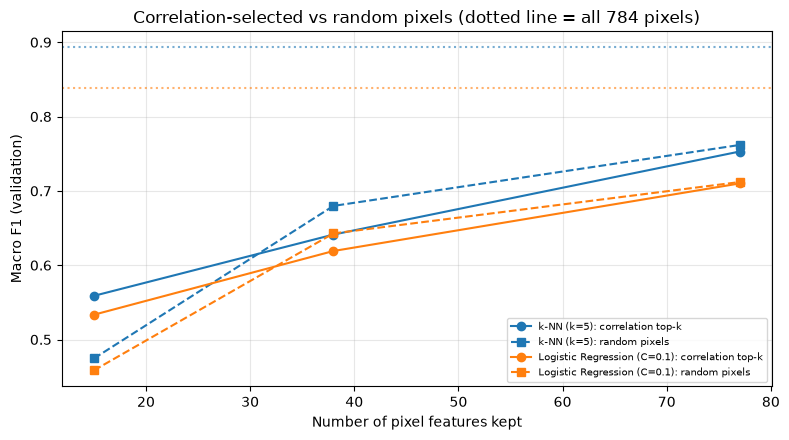

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for model_name, g in fs_table.groupby("model", sort=False):
    sel = g[g["dataset"].str.startswith("Top")]
    rnd = g[g["dataset"].str.startswith("Random")]
    full = g[g["dataset"] == "All 784 pixels"].iloc[0]
    line, = ax.plot(sel["n_features"], sel["macro_f1"], marker="o", label=f"{model_name}: correlation top-k")
    ax.plot(rnd["n_features"], rnd["macro_f1"], marker="s", linestyle="--", color=line.get_color(), label=f"{model_name}: random pixels")
    ax.axhline(full["macro_f1"], color=line.get_color(), linestyle=":", alpha=0.6)
ax.set_xlabel("Number of pixel features kept")
ax.set_ylabel("Macro F1 (validation)")
ax.set_title("Correlation-selected vs random pixels (dotted line = all 784 pixels)")
ax.grid(alpha=0.3)
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_feature_selection_f1.png", dpi=150)
plt.show()

## 6. PCA 

PCA is fitted on the training images only, then the first m components are used as the features. Components are ordered by explained variance, so one fit with 200 components covers every smaller m.

PCA turns the 784 pixels into a smaller set of new features called principal components. Each component is a weighted mix of all 784 pixels. PCA picks them from the training images: the first component captures the biggest variation between drawings, the second captures the next biggest, and so on. That’s why the curve rises quickly and then flattens. The first components hold most of the information, and the later ones mostly add small details and noise. So we can keep only the first m components and still keep most of the information with far fewer than 784 features. PCA was fitted on the training images only and then applied to the validation images, so the validation data doesn’t affect which components are chosen.

Keeping a subset of pixels is different. The other pixels are thrown away completely, but the kept ones are real pixels, so you can easily see where they are on the image. With PCA every component uses all the pixels, so the information is compressed rather than cut. Some is still lost when the later components are dropped, but those mostly hold noise. This suits drawings because neighbouring pixels are often very similar, and PCA can merge them into one feature. The downsides are that components are hard to interpret, since each one is a mix of many pixels, and that PCA picks components by how much the images vary, not by how well they separate the classes.

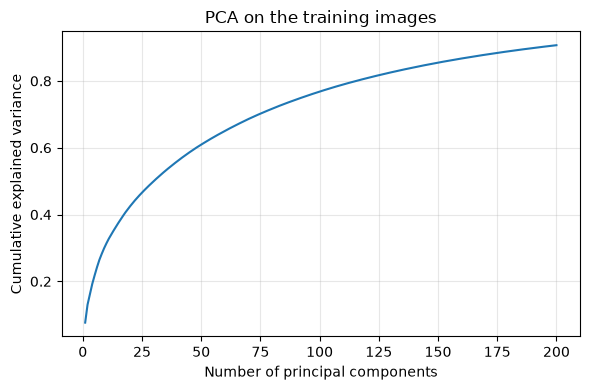

 10 components keep  31.4% of the variance
 20 components keep  42.5% of the variance
 50 components keep  60.9% of the variance
100 components keep  76.8% of the variance
200 components keep  90.7% of the variance


In [8]:
pca = PCA(n_components=200, random_state=SEED).fit(X_tr)
Z_tr, Z_va = pca.transform(X_tr), pca.transform(X_va)
cum_var = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, 201), cum_var)
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_title("PCA on the training images")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_pca_variance.png", dpi=150)
plt.show()
for m in (10, 20, 50, 100, 200):
    print(f"{m:3d} components keep {cum_var[m-1]*100:5.1f}% of the variance")

In [9]:
rows = []
for m in (10, 20, 30, 50, 100, 200):
    for model_name, model in make_models().items():
        res = evaluate(model, Z_tr[:, :m], y_tr, Z_va[:, :m], y_va)
        rows.append({"dataset": f"PCA {m} components", "n_features": m, "model": model_name,
                     "variance_kept": cum_var[m - 1], **res})
        print(f"PCA {m:3d} {model_name:28s} acc {res['accuracy']:.4f}  F1 {res['macro_f1']:.4f}  ({res['time_s']:.1f}s)")
pca_table = pd.DataFrame(rows)
pca_table.round(4).to_csv(results_dir / "quickdraw_pca.csv", index=False)

for model_name, g in pca_table.groupby("model", sort=False):
    t = g.drop(columns="model").round(4).reset_index(drop=True)
    print(model_name)
    try:
        display(t.style.highlight_max(subset=["macro_f1"], props="font-weight: bold; background-color: #d6f5d6"))
    except Exception:
        display(t)

PCA  10 k-NN (k=5)                   acc 0.8696  F1 0.8691  (0.1s)
PCA  10 Logistic Regression (C=0.1)  acc 0.7783  F1 0.7759  (0.1s)
PCA  20 k-NN (k=5)                   acc 0.9029  F1 0.9022  (0.1s)
PCA  20 Logistic Regression (C=0.1)  acc 0.8204  F1 0.8190  (0.1s)
PCA  30 k-NN (k=5)                   acc 0.9121  F1 0.9118  (0.1s)
PCA  30 Logistic Regression (C=0.1)  acc 0.8300  F1 0.8293  (0.1s)
PCA  50 k-NN (k=5)                   acc 0.9121  F1 0.9114  (0.1s)
PCA  50 Logistic Regression (C=0.1)  acc 0.8400  F1 0.8391  (0.2s)
PCA 100 k-NN (k=5)                   acc 0.9121  F1 0.9110  (0.1s)
PCA 100 Logistic Regression (C=0.1)  acc 0.8421  F1 0.8414  (2.1s)
PCA 200 k-NN (k=5)                   acc 0.9042  F1 0.9024  (0.1s)
PCA 200 Logistic Regression (C=0.1)  acc 0.8396  F1 0.8391  (1.5s)
k-NN (k=5)


,dataset,n_features,variance_kept,accuracy,macro_precision,macro_recall,macro_f1,time_s
0,PCA 10 components,10,0.314200,0.869600,0.870800,0.869600,0.869100,0.130000
1,PCA 20 components,20,0.425200,0.902900,0.904000,0.902900,0.902200,0.053500
2,PCA 30 components,30,0.500500,0.912100,0.913100,0.912100,0.911800,0.059600
3,PCA 50 components,50,0.609400,0.912100,0.912700,0.912100,0.911400,0.081400
4,PCA 100 components,100,0.768100,0.912100,0.913000,0.912100,0.911000,0.103800
5,PCA 200 components,200,0.907000,0.904200,0.907000,0.904200,0.902400,0.143600


Logistic Regression (C=0.1)


,dataset,n_features,variance_kept,accuracy,macro_precision,macro_recall,macro_f1,time_s
0,PCA 10 components,10,0.314200,0.778300,0.774900,0.778300,0.775900,0.104400
1,PCA 20 components,20,0.425200,0.820400,0.818600,0.820400,0.819000,0.114700
2,PCA 30 components,30,0.500500,0.830000,0.828900,0.830000,0.829300,0.130300
3,PCA 50 components,50,0.609400,0.840000,0.838800,0.840000,0.839100,0.170600
4,PCA 100 components,100,0.768100,0.842100,0.841100,0.842100,0.841400,2.108900
5,PCA 200 components,200,0.907000,0.839600,0.839000,0.839600,0.839100,1.525600


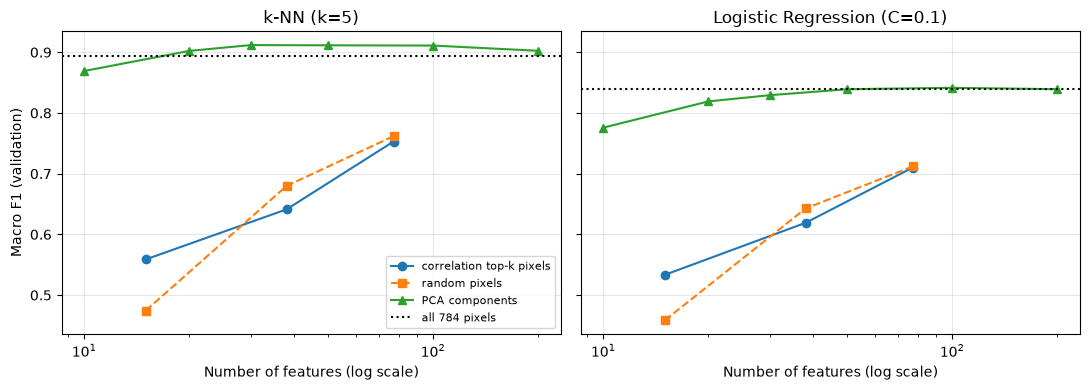

In [10]:
# one picture comparing all three ways of reducing the input (validation macro F1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, model_name in zip(axes, make_models().keys()):
    fsm = fs_table[(fs_table["model"] == model_name)]
    sel = fsm[fsm["dataset"].str.startswith("Top")]
    rnd = fsm[fsm["dataset"].str.startswith("Random")]
    pc = pca_table[pca_table["model"] == model_name]
    full = fsm[fsm["dataset"] == "All 784 pixels"].iloc[0]["macro_f1"]
    ax.plot(sel["n_features"], sel["macro_f1"], "o-", label="correlation top-k pixels")
    ax.plot(rnd["n_features"], rnd["macro_f1"], "s--", label="random pixels")
    ax.plot(pc["n_features"], pc["macro_f1"], "^-", label="PCA components")
    ax.axhline(full, color="k", linestyle=":", label="all 784 pixels")
    ax.set_xscale("log")
    ax.set_xlabel("Number of features (log scale)")
    ax.set_title(model_name)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Macro F1 (validation)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_feature_reduction_comparison.png", dpi=150)
plt.show()

## 7. Findings: feature subsets and PCA

1. The best correlation dataset for both models was Top 10 per class (77 pixels): macro F1 0.7530 for k-NN and 0.7100 for Logistic Regression. Top 5 (38 pixels) got 0.6412 and 0.6191 and top 2 (15 pixels) got 0.5588 and 0.5334. The best subset is still ~14 points (k-NN) and ~13 points (Logistic Regression) behind using all 784 pixels (0.8930 and 0.8387). The models are fast but lose a lot of accuracy keeping less than 10% of the pixels.

2. Correlation-based selection only outperformed random pixels in the smallest size. It won clearly with 15 pixels (k-NN 0.5588 vs 0.4745, Logistic Regression 0.5334 vs 0.4585). random did better with 38 pixels (0.6798 vs 0.6412 and 0.6428 vs 0.6191) and about the same with 77 pixels (0.7618 vs 0.7530 and 0.7119 vs 0.7100) We only tested a random set per size, so these results might vary when you use a different seed.

3. Each class has its own useful areas. For tree its an arch across the top where the leafy part is drawn. Tree has the strongest single pixel (0.503) Bicycle is the left and right wheels (0.420), apple is the stem and bottom of body (0.375), house is the bottom corners and roof tip (0.384), guitar is the body in the center (0.398) and cat is the ears at the top. Cat (0.224) and aeroplane (0.230) are least reliable, with weak best pixels and spread out maps because people draw in many different ways. Airplane’s best pixel (row 13, column 25) is adjacent to fish’s (row 12, column 25), since they’re both long horizontal shapes that extend to the image edges. This fits with CNN’s habit of blurring the two.

4. PCA performed better than pixel selection. For k-NN, 20 components (42.5% of variance) were already better than all 784 pixels (0.9022 vs 0.8930), the best was 30 components (0.9118). For Logistic Regression about 50 components matched all pixels (0.8391 vs 0.8387). And best was 100 components (0.8414). This benefits k-NN the most, because it relies on distances between images, and PCA gets rid of the noisy pixels that mess up those distances. Logistic Regression already learns a weight for each pixel so it can ignore noise by itself.

5. One-vs-rest correlation is a bad criterion for picture.  It also assumes that objects are drawn in the same place, but drawings move and resize. Neighbouring pixels have similar correlations so the selected pixels form clumps that carry repeated information, whereas random pixels cover more of the image. This is likely why random did better or as good starting from 38 pixels. The pixels for each class are also selected separately. Thus, similar classes like aeroplane and fish could have nearly identical pixels.

## 8. Clustering

Clustering never sees the labels. The labels are only used afterwards to ask how well the clusters match the 8 drawing classes. All clustering is done on the training images.

K-means is unsupervised, so it never gets to see the labels. It clusters the images into k groups (here k = 8) according to the similarity of their pixel values. It does this by randomly selecting 8 center points (centroids) then assigning each image to the nearest centroid, and moving each centroid to the mean of the images assigned to it. It iterates these two steps until the groups stabilise. The result depends on the random starting points, so we set n_init=10: k-means runs 10 times and keeps the run where images are closest to their centroids overall.

The clustering results cannot be compared directly to classifier accuracy. The labels are used to train a classifier, and accuracy is the fraction of times the classifier gets the label right. K-means never sees the labels, so its cluster numbers (0 to 7) are not associated with our class numbers: cluster 3 is not “cat” just because cat is class 3. It clusters images based on visual similarity, e.g. size or amount of ink, thus one cluster may contain several classes and one class may be scattered across several clusters. That is why we use ARI, NMI and purity which measure how well clusters match the true classes without requiring the cluster numbers to match the class numbers. These scores are not on the same scale as accuracy (a purity of 0.6 is not 60% accuracy). Clustering has no help from labels, and so is expected to score worse than a classifier.

k-means (k=8) on 784 pixels: 6.7s


class,airplane,apple,bicycle,cat,fish,guitar,house,tree
cluster,,,,,,,,
0,25,814,14,291,5,6,1341,19
1,1619,10,354,432,362,587,25,37
2,75,35,11,70,5,761,97,183
3,5,1434,7,252,19,1,587,1
4,204,9,1775,951,94,127,172,39
5,381,82,192,249,1886,26,98,76
6,26,6,37,72,15,875,5,11
7,65,10,10,83,14,17,75,2034


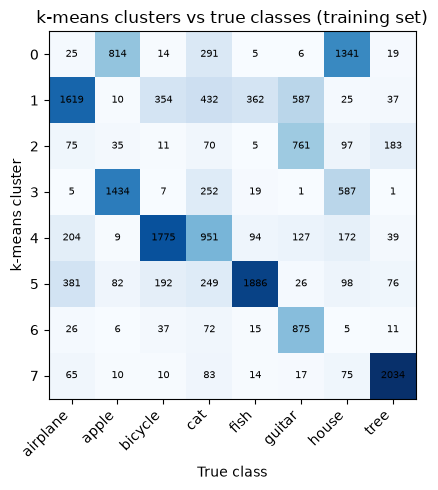

In [11]:
def purity(labels_true, labels_pred):
    """Share of images that belong to the majority class of their cluster."""
    total = 0
    for c in np.unique(labels_pred):
        total += np.bincount(labels_true[labels_pred == c]).max()
    return total / len(labels_true)

def cluster_scores(name, X_for_sil, labels):
    return {"method": name,
            "ARI": adjusted_rand_score(y_tr, labels),
            "NMI": normalized_mutual_info_score(y_tr, labels),
            "homogeneity": homogeneity_score(y_tr, labels),
            "completeness": completeness_score(y_tr, labels),
            "purity": purity(y_tr, labels),
            "silhouette": silhouette_score(X_for_sil, labels, sample_size=5000, random_state=SEED)}

start = time.perf_counter()
km = KMeans(n_clusters=n_classes, n_init=10, random_state=SEED).fit(X_tr)
km_labels = km.labels_
print(f"k-means (k=8) on 784 pixels: {time.perf_counter()-start:.1f}s")

# contingency table: rows = clusters, columns = true classes
cont = pd.crosstab(pd.Series(km_labels, name="cluster"), pd.Series([categories[i] for i in y_tr], name="class"))
display(cont)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(cont.values, cmap="Blues")
ax.set_xticks(range(n_classes)); ax.set_xticklabels(cont.columns, rotation=45, ha="right")
ax.set_yticks(range(n_classes)); ax.set_yticklabels(cont.index)
for i in range(cont.shape[0]):
    for j in range(cont.shape[1]):
        ax.text(j, i, cont.values[i, j], ha="center", va="center", fontsize=7)
ax.set_xlabel("True class"); ax.set_ylabel("k-means cluster")
ax.set_title("k-means clusters vs true classes (training set)")
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_kmeans_vs_classes.png", dpi=150)
plt.show()

### 8.1 Choosing the number of clusters (elbow and silhouette)

k= 2 inertia   747107.8 silhouette 0.1026
k= 3 inertia   703087.9 silhouette 0.1081
k= 4 inertia   678659.2 silhouette 0.0802
k= 5 inertia   659274.8 silhouette 0.0771
k= 6 inertia   641705.6 silhouette 0.0822
k= 7 inertia   624675.5 silhouette 0.0876
k= 8 inertia   608863.4 silhouette 0.0838
k= 9 inertia   597565.0 silhouette 0.0864
k=10 inertia   587082.0 silhouette 0.0854
k=11 inertia   578579.6 silhouette 0.0875
k=12 inertia   573547.4 silhouette 0.0797


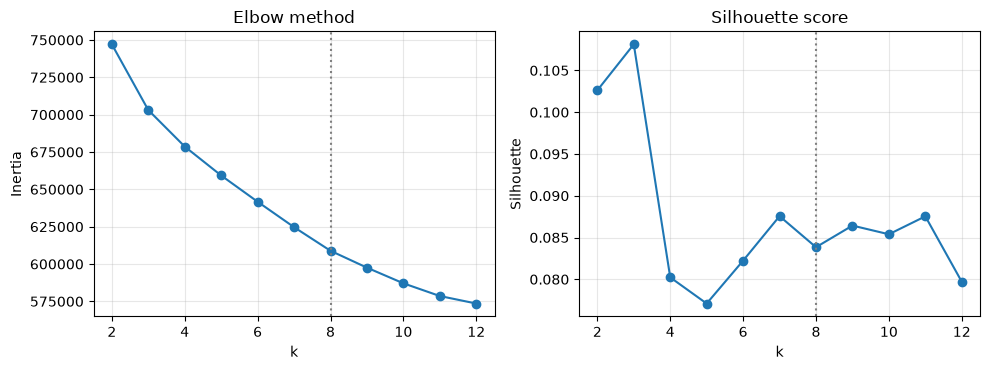

In [12]:
# k-means on the first 50 PCA components of the training set (much faster than 784 pixels, similar structure)
Z50 = Z_tr[:, :50]
ks = list(range(2, 13))
inertia, sil = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(Z50)
    inertia.append(m.inertia_)
    sil.append(silhouette_score(Z50, m.labels_, sample_size=5000, random_state=SEED))
    print(f"k={k:2d} inertia {m.inertia_:10.1f} silhouette {sil[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(ks, inertia, "o-"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow method")
axes[1].plot(ks, sil, "o-"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette"); axes[1].set_title("Silhouette score")
for ax in axes:
    ax.axvline(8, color="grey", linestyle=":")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_kmeans_elbow_silhouette.png", dpi=150)
plt.show()
pd.DataFrame({"k": ks, "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 4)}).to_csv(results_dir / "quickdraw_kmeans_k_search.csv", index=False)

### 8.2 A second clustering algorithm (Gaussian mixture) and comparison

In [13]:
gmm = GaussianMixture(n_components=n_classes, covariance_type="diag", random_state=SEED).fit(Z50)
gmm_labels = gmm.predict(Z50)
km50 = KMeans(n_clusters=n_classes, n_init=10, random_state=SEED).fit(Z50)

cluster_table = pd.DataFrame([
    cluster_scores("k-means, 784 pixels (k=8)", X_tr, km_labels),
    cluster_scores("k-means, 50 PCA components (k=8)", Z50, km50.labels_),
    cluster_scores("Gaussian mixture, 50 PCA components (8 comps, diagonal)", Z50, gmm_labels),
]).round(4)
cluster_table.to_csv(results_dir / "quickdraw_clustering.csv", index=False)
try:
    display(cluster_table.style.highlight_max(subset=["ARI", "NMI", "purity", "silhouette"], props="font-weight: bold; background-color: #d6f5d6"))
except Exception:
    display(cluster_table)

,method,ARI,NMI,homogeneity,completeness,purity,silhouette
0,"k-means, 784 pixels (k=8)",0.365500,0.458400,0.451100,0.465900,0.610700,0.041800
1,"k-means, 50 PCA components (k=8)",0.364500,0.457400,0.450200,0.464900,0.610100,0.083800
2,"Gaussian mixture, 50 PCA components (8 comps, diagonal)",0.197900,0.437000,0.405300,0.474200,0.517600,0.037300


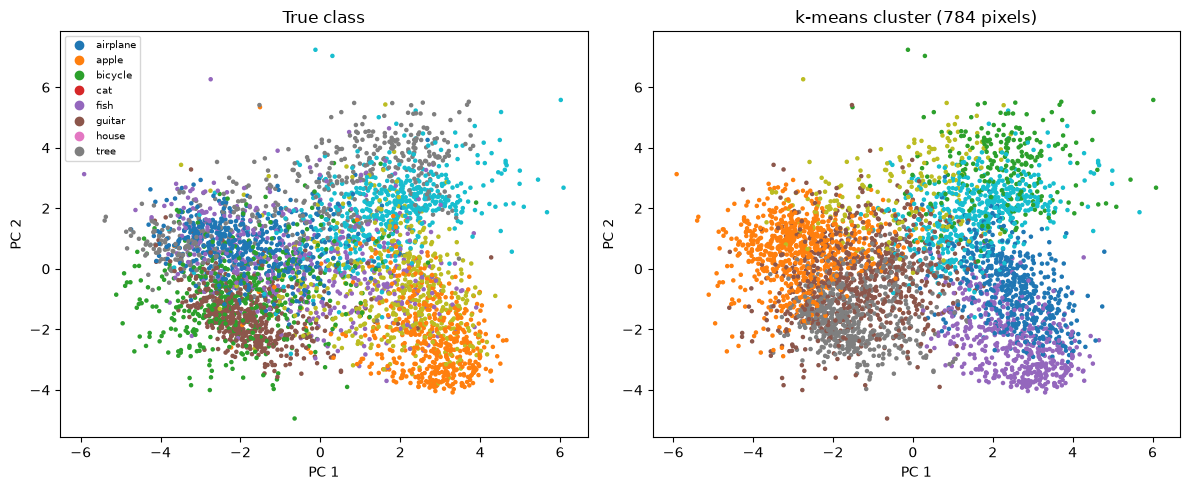

In [14]:
# 2-D PCA picture of the training images: coloured by true class and by k-means cluster
sample = np.random.default_rng(SEED).choice(len(X_tr), size=4000, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, labels, title in [(axes[0], y_tr[sample], "True class"), (axes[1], km_labels[sample], "k-means cluster (784 pixels)")]:
    sc = ax.scatter(Z_tr[sample, 0], Z_tr[sample, 1], c=labels, cmap="tab10", s=5)
    ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.set_title(title)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=plt.cm.tab10(i / 9), label=categories[i]) for i in range(n_classes)]
axes[0].legend(handles=handles, fontsize=7, loc="best")
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_pca_2d_clusters.png", dpi=150)
plt.show()

### 9. Findings: clusters

1. The k-means clusters only partially match the 8 classes: ARI 0.3655, NMI 0.4584, purity 0.6107. One cluster is majority in its own class in about 61% of the images, which is above the chance level of 12.5% but far from perfect. Some classes get their own cluster: tree (2,034 of 2,400 in cluster 7), fish (1,886), bicycle (1,775) and aeroplane (1,619). Apple and house are mixed in two clusters (cluster 0: 1,341 houses and 814 apples; cluster 3: 1,434 apples and 587 houses), probably because they are both simple closed shapes in the center of the image. Cat does not have its own cluster, but is spread over almost all clusters (951 in bicycle cluster, 432 in aeroplane cluster). The guitar is divided into two groups (761 and 875).

2. The plots do not suggest k = 8. The inertia drops smoothly from 747,108 (k = 2) to 573,547 (k = 12) without a clear elbow. Silhouette is highest at k=3 (0.1081) and only 0.0838 at k=8. All silhouette scores are below 0.11 indicating large overlap between clusters. This means there are not 8 natural groups of drawings in the pixel space. It looks like k-means is grouping images by size, position and amount of ink rather than object. We kept only k = 8 so that we would be able to compare the clusters with the 8 classes.

3. Gaussian mixture performed worse than k-means on the same 50 PCA components: ARI 0.1979 vs 0.3645, purity 0.5176 vs 0.6101, NMI 0.4370 vs 0.4574. It was the most complete (0.4742) meaning it kept classes together, but made more mixed clusters. Maybe the diagonal covariance is too simple for this data. K-means on 50 PCA components obtained almost the same result as on all 784 pixels (ARI 0.3645 vs 0.3655), so PCA preserved the cluster structure while making it much faster.

4. The supervised models do much better: on validation, Logistic Regression got 0.8392, k-NN 0.8954, the MLP 0.9033 and the CNN 0.9554, against the best clustering purity of 0.6107. It’s not a like for like comparison. While the classifiers learn from labels, clustering never sees them. Purity is not accuracy since it allows two clusters per class (guitar) and classes with no cluster (cat). The clustering scores are also on the training set not on the validation set. However, tree, fish and bicycle mostly form their own clusters without labels which indicates that the pixels contain lots of class information.